# Quality control

Run from the repository root after `python -m scripts.download_data` and `python -m scripts.run_analysis`. These notebooks use reusable functions from `src/`. Observations come from GSE45827, not from the historical coursework.

## Research question

Do the selected intensities show missingness, unusual distributions, or broad variation?

## Data and methods

Map probes to genes without using group differences; inspect per-sample medians and PCA.

          subtype batch  median_intensity  iqr_intensity  missing_fraction
count          59    59         59.000000      59.000000              59.0
unique          2     5               NaN            NaN               NaN
top     Luminal B     2               NaN            NaN               NaN
freq           30    13               NaN            NaN               NaN
mean          NaN   NaN          7.469504       3.980099               0.0
std           NaN   NaN          0.117696       0.103770               0.0
min           NaN   NaN          7.176120       3.767495               0.0
25%           NaN   NaN          7.370460       3.900877               0.0
50%           NaN   NaN          7.483350       3.981770               0.0
75%           NaN   NaN          7.575805       4.058568               0.0
max           NaN   NaN          7.665200       4.201210               0.0
PCA variance: [0.15210991 0.09290161]


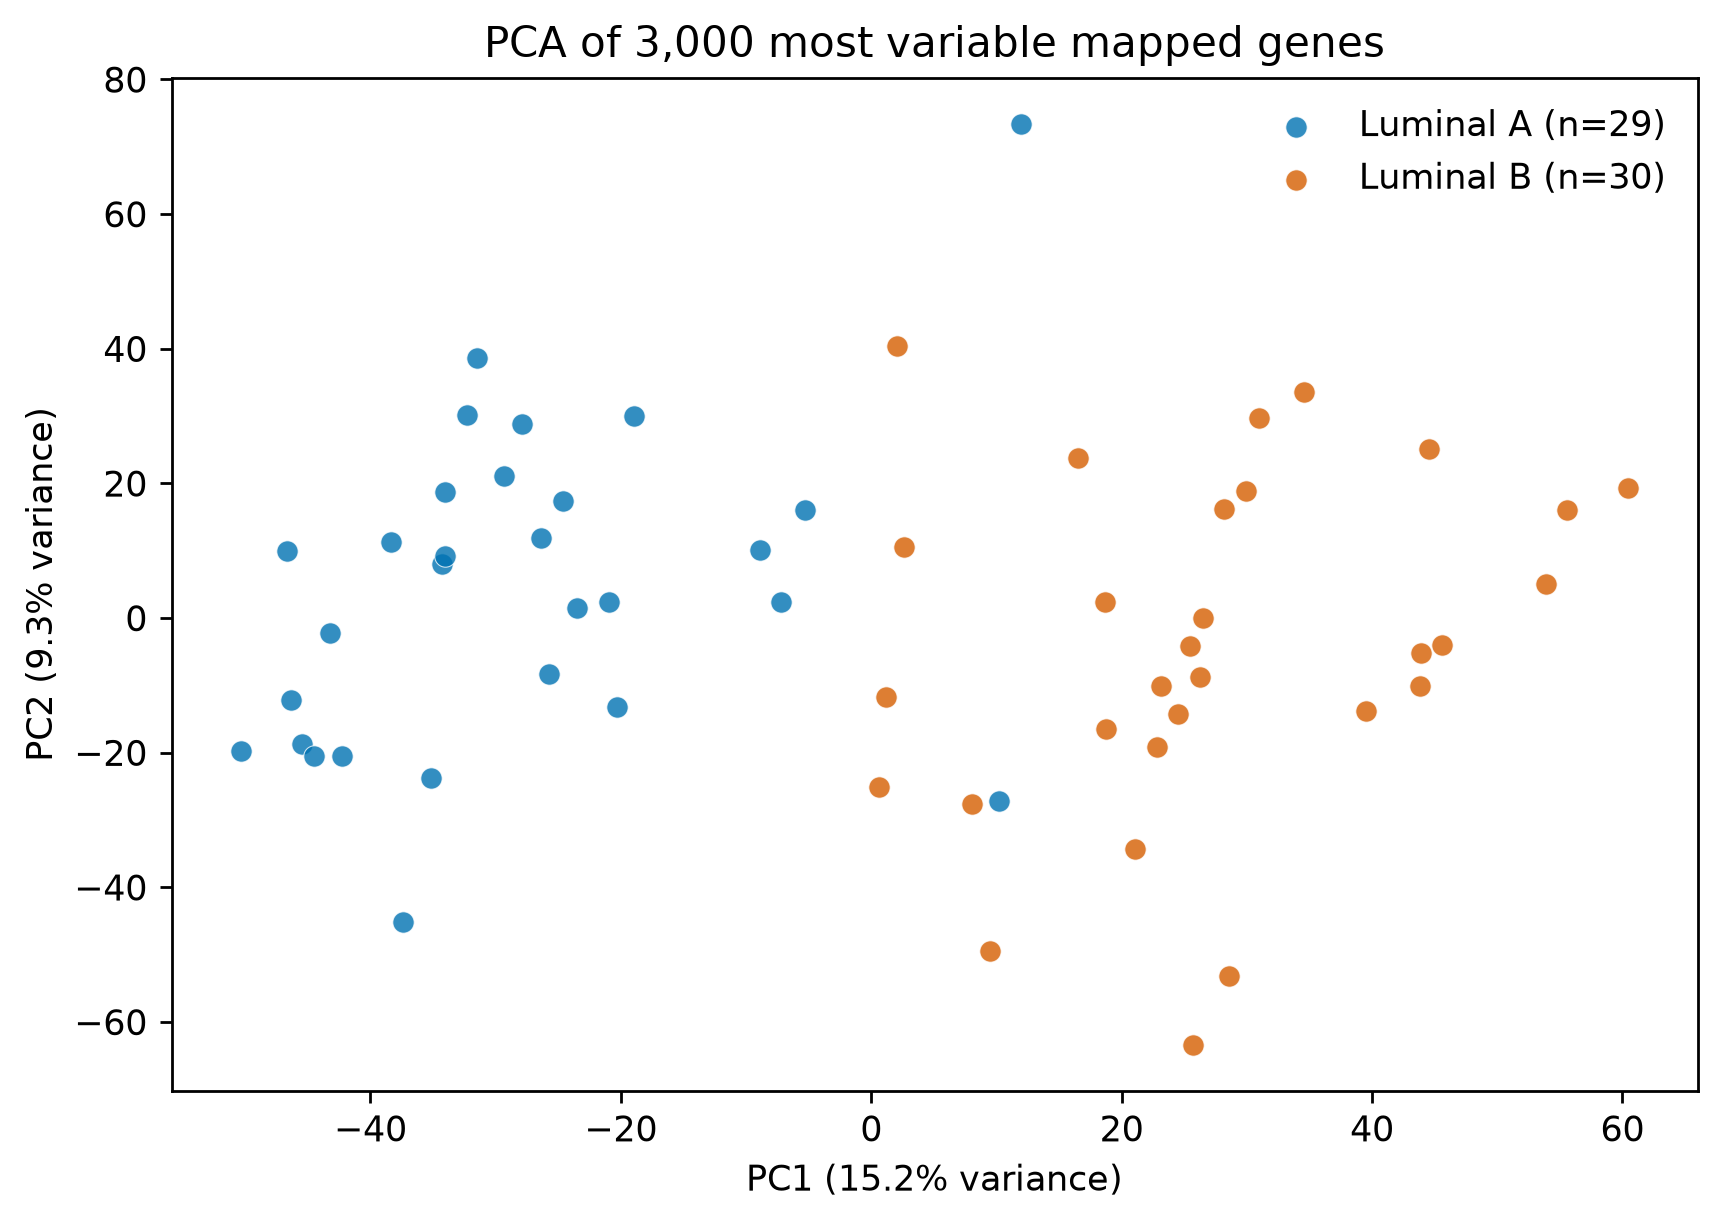

In [1]:
from pathlib import Path
from src.data_loading import parse_geo, load_annotation
from src.preprocessing import select_samples, gene_matrix
from src.quality_control import qc_metrics, pca
from src.visualization import pca_plot
expression, all_metadata = parse_geo(Path('data/raw/GSE45827_series_matrix.txt.gz'))
selected, metadata = select_samples(expression, all_metadata)
genes, mapping = gene_matrix(selected, load_annotation(Path('data/raw/GPL570.annot.gz')))
metrics = qc_metrics(genes, metadata)
points, variance = pca(genes, metadata)
print(metrics[['subtype','batch','median_intensity','iqr_intensity','missing_fraction']].describe(include='all'))
print('PCA variance:', variance)
pca_plot(points, variance, Path('figures'))
from IPython.display import display, Image
display(Image(filename='figures/02_pca.png'))

## Biological interpretation

PCA displays broad sample variation; its axes are not proof of biological subtyping. No sample is excluded after viewing the plot.

## Limitations

Potential batch and tumour-purity variation remain; source preprocessing is not fully auditable.